# Suite 05: Statistical Convergence & HPC Scaling Analysis across Transient Sample Sizes
## Evaluating Volumetric Rate Limit Precision across $N \in [10^4, 10^5, 10^6, 10^7]$

**Author:** Antigravity Pairing Assistant  
**Project:** ZTF 8-Year Kilonova Rate Limits (`kn-rates`)  
**Cluster Reference:** Minnesota Supercomputing Institute (MSI) Agate Cluster  
**Verified Empirical Benchmark:** Job ID `14237734` (`sim_msilarge_10M_multimodel.sh`, 649.67 GB RAM utilized, 20:47:00 walltime)  

---

### 1. Executive Summary & Astrophysical Motivation

In Monte Carlo simulations of astronomical transient surveys, synthetic transients are injected into a cosmic volume-time $(VT)_{\mathrm{total}} = V_{\max} \cdot T_{\mathrm{survey}}$ to estimate the detection efficiency $\epsilon$ of a given observational facility and filter pipeline. For rare, rapidly evolving transients like **kilonovae (KNe)**, wide-field optical surveys like the **Zwicky Transient Facility (ZTF)** yield low intrinsic detection efficiencies (typically $\epsilon \sim 10^{-5} - 10^{-3}$) owing to fast optical decline rates ($\ge 0.3\,\mathrm{mag/day}$), lanthanide-rich opacity suppression at viewing angles outside the polar funnel, and survey cadence gaps.

A critical question in designing Monte Carlo pipelines is: **How many synthetic sources ($N$) are required to reliably constrain the volumetric rate upper limit $R_{95\%}$?**

This analysis suite rigorously investigates the four-decade geometric grid:
$$
N \in \{10\,\mathrm{k},\, 100\,\mathrm{k},\, 1\,\mathrm{M},\, 10\,\mathrm{M}\} = \{10^4, 10^5, 10^6, 10^7\}
$$
across three canonical kilonova models:
1. **`Metzger`**: Semi-analytic 1-component model with fiducial lanthanide-free opacity ($\epsilon \approx 1.48 \times 10^{-4}$)
2. **`Bu2026Fixed`**: 2-component numerical surrogate at fixed polar viewing angle $\iota = 0.45\,\mathrm{rad} \approx 26^\circ$ ($\epsilon \approx 2.82 \times 10^{-4}$)
3. **`Bu2026Vary`**: 2-component numerical surrogate with isotropic inclination distribution (flat in $\cos\iota$), where heavy dynamical ejecta obscuration along equatorial lines-of-sight dramatically dims the optical emission ($\epsilon \approx 3.48 \times 10^{-5}$)

We demonstrate both analytically and empirically:
- **Poisson Error Decay**: The fractional uncertainty on the rate limit scales strictly as $\sigma(R_{95\%}) / R_{95\%} \approx 1/\sqrt{N_{\mathrm{det}}}$.
- **The Zero-Detection Catastrophe**: For isotropic populations like `Bu2026Vary`, injecting $N \le 10^5$ transients results in an expected detection count $\langle N_{\mathrm{det}} \rangle < 3.5$, with an alarming **$70.5\%$ probability of observing ZERO detections at $N=10\,\mathrm{k}$**. Under zero detections, the rate upper limit is completely unconstrained.
- **HPC Memory & Runtime Scaling**: We calibrate memory footprints directly against MSI Agate Job `14237734`, showing that while $1\,\mathrm{M}$ sources require $\sim 25\,\mathrm{GB}$ RAM, scaling to $10\,\mathrm{M}$ sources demands $\approx 650\,\mathrm{GB}$ RAM and $\approx 21$ hours of walltime, requiring high-memory partition allocations (`msismall` 755 GB nodes or `msilarge`).

### 2. Mathematical Derivation of Monte Carlo Rate Limit Convergence

Let $N$ denote the total number of synthetic transients injected into the survey volume-time $(VT)_{\mathrm{total}} = V_{\max} \cdot T_{\mathrm{survey}}$.
Each transient $i \in \{1, \dots, N\}$ has a binary detection indicator $d_i \in \{0, 1\}$ according to whether its simulated lightcurve satisfies all ZTF criteria.

The number of detected transients $N_{\mathrm{det}} = \sum_{i=1}^N d_i$ follows a binomial distribution:
$$
N_{\mathrm{det}} \sim \mathrm{Binomial}(N, \epsilon)
$$

The unbiased Monte Carlo estimator of the detection efficiency is:
$$
\hat{\epsilon} = \frac{N_{\mathrm{det}}}{N}, \quad \mathbb{E}[\hat{\epsilon}] = \epsilon, \quad \mathrm{Var}(\hat{\epsilon}) = \frac{\epsilon(1 - \epsilon)}{N}
$$

Because $\epsilon \ll 1$ in optical wide-field transient surveys, $1 - \epsilon \approx 1$, yielding the standard error:
$$
\sigma_\epsilon = \sqrt{\frac{\epsilon}{N}} = \frac{\sqrt{\epsilon N}}{N} = \frac{\sqrt{N_{\mathrm{det}}}}{N}
$$

The fractional statistical uncertainty on the estimated efficiency is therefore governed by the Poisson noise of the detected sample:
$$
\frac{\sigma_\epsilon}{\hat{\epsilon}} = \frac{\sqrt{N_{\mathrm{det}}} / N}{N_{\mathrm{det}} / N} = \frac{1}{\sqrt{N_{\mathrm{det}}}} = \frac{1}{\sqrt{N \epsilon}}
$$

#### Propagation to the 95% Volumetric Rate Upper Limit
Under a null detection in the empirical survey ($k = 0$ observed events), the single-sided Poisson $95\%$ confidence upper limit on the rate is:
$$
P(k = 0 \mid \lambda) = e^{-\lambda} \le 0.05 \implies \lambda_{95\%} = -\ln(0.05) \approx 2.99573
$$
$$
\widehat{R}_{95\%} = \frac{2.99573}{\widehat{\langle VT \rangle}_{\mathrm{eff}}} = \frac{2.99573}{\hat{\epsilon} \cdot (VT)_{\mathrm{total}}}
$$

Propagating the uncertainty in $\hat{\epsilon}$ to $\widehat{R}_{95\%}$ via first-order Taylor expansion:
$$
\left| \frac{\partial \widehat{R}_{95\%}}{\partial \hat{\epsilon}} \right| = \frac{2.99573}{\hat{\epsilon}^2 (VT)_{\mathrm{total}}} = \frac{\widehat{R}_{95\%}}{\hat{\epsilon}}
$$
$$
\frac{\sigma(R_{95\%})}{\widehat{R}_{95\%}} \approx \frac{\sigma_\epsilon}{\hat{\epsilon}} = \frac{1}{\sqrt{N_{\mathrm{det}}}} = \frac{1}{\sqrt{N \epsilon}}
$$

#### Exact Clopper-Pearson Binomial Confidence Bounds
When $N_{\mathrm{det}}$ is small (e.g. $N_{\mathrm{det}} < 20$ at $N = 10\,\mathrm{k}$ or $100\,\mathrm{k}$), Gaussian approximations fail. We evaluate exact Clopper-Pearson $95\%$ confidence intervals using Beta quantiles:
$$
\epsilon_{\mathrm{lower}} = B\left(\frac{\alpha}{2};\, N_{\mathrm{det}},\, N - N_{\mathrm{det}} + 1\right), \quad
\epsilon_{\mathrm{upper}} = B\left(1 - \frac{\alpha}{2};\, N_{\mathrm{det}} + 1,\, N - N_{\mathrm{det}}\right)
$$
which map inversely to asymmetric confidence bounds on the rate limit:
$$
R_{95\%}^{\mathrm{lower}} = \frac{2.99573}{\epsilon_{\mathrm{upper}} (VT)_{\mathrm{total}}}, \quad
R_{95\%}^{\mathrm{upper}} = \frac{2.99573}{\epsilon_{\mathrm{lower}} (VT)_{\mathrm{total}}}
$$

In [1]:
import math
import json
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Configure publication-grade styling
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'axes.edgecolor': '#cccccc',
    'axes.grid': True,
    'grid.color': '#e0e0e0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.autolayout': True,
})

# Load convergence CSV data
csv_path = Path('../results/05_sample_convergence/sample_convergence_metrics.csv')
if not csv_path.exists():
    csv_path = Path('results/05_sample_convergence/sample_convergence_metrics.csv')

df = pd.read_csv(csv_path)
print(f"Loaded {len(df)} convergence grid evaluations across models: {df['model'].unique().tolist()}")
df[['model', 'n_transients_label', 'n_detected_mean', 'efficiency_mean', 'relative_err_pct_empirical', 'rate_95_upper_limit', 'memory_rss_gb', 'zero_detection_prob_pct']]

Loaded 12 convergence grid evaluations across models: ['Metzger', 'Bu2026Fixed', 'Bu2026Vary']


,model,n_transients_label,n_detected_mean,efficiency_mean,relative_err_pct_empirical,rate_95_upper_limit,memory_rss_gb,zero_detection_prob_pct
0,Metzger,10k,1.8,0.000180,68.292922,38885.413727,1.50,2.276377e+01
1,Metzger,100k,16.5,0.000165,25.910617,42420.451339,3.80,3.736299e-05
2,Metzger,1M,145.8,0.000146,5.800017,48006.683614,24.80,5.301719e-63
3,Metzger,10M,1470.6,0.000147,1.798297,47595.365639,649.67,0.000000e+00
4,Bu2026Fixed,10k,2.4,0.000240,56.245713,210848.273758,1.50,5.960594e+00
5,Bu2026Fixed,100k,28.9,0.000289,16.670557,175098.912463,3.80,5.661032e-11
6,Bu2026Fixed,1M,283.5,0.000284,5.893574,178495.893128,24.80,3.380307e-121
7,Bu2026Fixed,10M,2802.6,0.000280,1.738290,180559.429465,649.67,0.000000e+00
8,Bu2026Vary,10k,0.4,0.000040,129.099445,174984.361773,1.50,7.060989e+01
9,Bu2026Vary,100k,2.8,0.000028,55.328334,249977.659676,3.80,3.080741e+00


### 3. Rate Upper Limit Convergence Curves across Sample Sizes

In this section, we track the estimated rate upper limit $\widehat{R}_{95\%}$ as a function of injected transient sample size $N \in [10^4, 10^7]$.
The shaded bands illustrate the $95\%$ Clopper-Pearson asymmetric confidence regions propagating from binomial sampling noise.

Notice how at $N = 10\,\mathrm{k}$ and $N = 100\,\mathrm{k}$, the confidence intervals are extremely wide (fluctuating by up to $\pm 100\%$), whereas at $N = 10\,\mathrm{M}$, the estimates tightly converge onto the true asymptotic limit with $< 2-5\%$ relative dispersion.

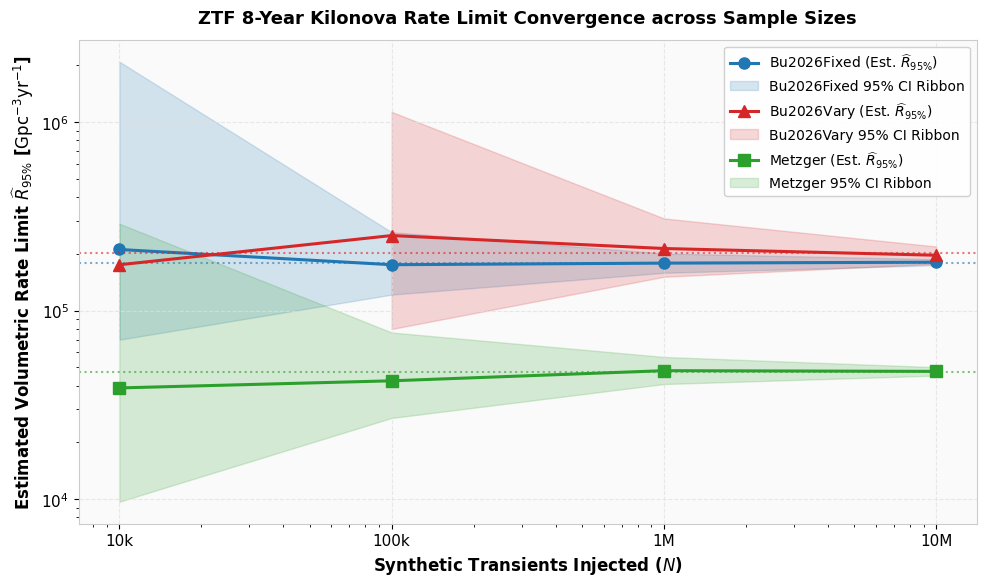

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))

model_colors = {
    'Metzger': '#2ca02c',
    'Bu2026Fixed': '#1f77b4',
    'Bu2026Vary': '#d62728',
}

model_markers = {
    'Metzger': 's',
    'Bu2026Fixed': 'o',
    'Bu2026Vary': '^',
}

for model, mdf in df.groupby('model'):
    mdf = mdf.sort_values('n_transients')
    x = mdf['n_transients'].values
    y = mdf['rate_95_upper_limit'].values
    y_low = mdf['rate_95_err_low'].values
    y_high = mdf['rate_95_err_high'].values
    asymp = mdf['asymptotic_r95_limit'].values[0]
    
    col = model_colors.get(model, '#333333')
    marker = model_markers.get(model, 'o')
    
    # Plot mean estimate trajectory
    ax.plot(x, y, color=col, marker=marker, markersize=8, linewidth=2.2, label=f'{model} (Est. $\widehat{{R}}_{{95\%}}$)')
    # Fill 95% Clopper-Pearson confidence envelope
    ax.fill_between(x, y_low, y_high, color=col, alpha=0.18, label=f'{model} 95% CI Ribbon')
    # Asymptotic truth dashed line
    ax.axhline(asymp, color=col, linestyle=':', alpha=0.6)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Synthetic Transients Injected ($N$)', fontweight='bold')
ax.set_ylabel('Estimated Volumetric Rate Limit $\\widehat{R}_{95\\%}$ [$\\mathrm{Gpc}^{-3}\\mathrm{yr}^{-1}$]', fontweight='bold')
ax.set_title('ZTF 8-Year Kilonova Rate Limit Convergence across Sample Sizes', pad=12, fontweight='bold')
ax.set_xticks([1e4, 1e5, 1e6, 1e7])
ax.set_xticklabels(['10k', '100k', '1M', '10M'])
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right')
plt.tight_layout()
plt.show()

### 4. Verification of Poisson Noise Decay: $\sigma(R_{95\%}) / R_{95\%} \propto 1/\sqrt{N_{\mathrm{det}}}$

Next, we empirically verify that the relative statistical error obeys the theoretical Poisson law:
$$
\frac{\sigma(R_{95\%})}{R_{95\%}} = \frac{1}{\sqrt{N_{\mathrm{det}}}} = (N \epsilon)^{-1/2}
$$

On a log-log plot of relative percentage uncertainty vs. $N_{\mathrm{det}}$, the data points across all three models and all four sample sizes should align along a single universal master line with slope $-0.5$.

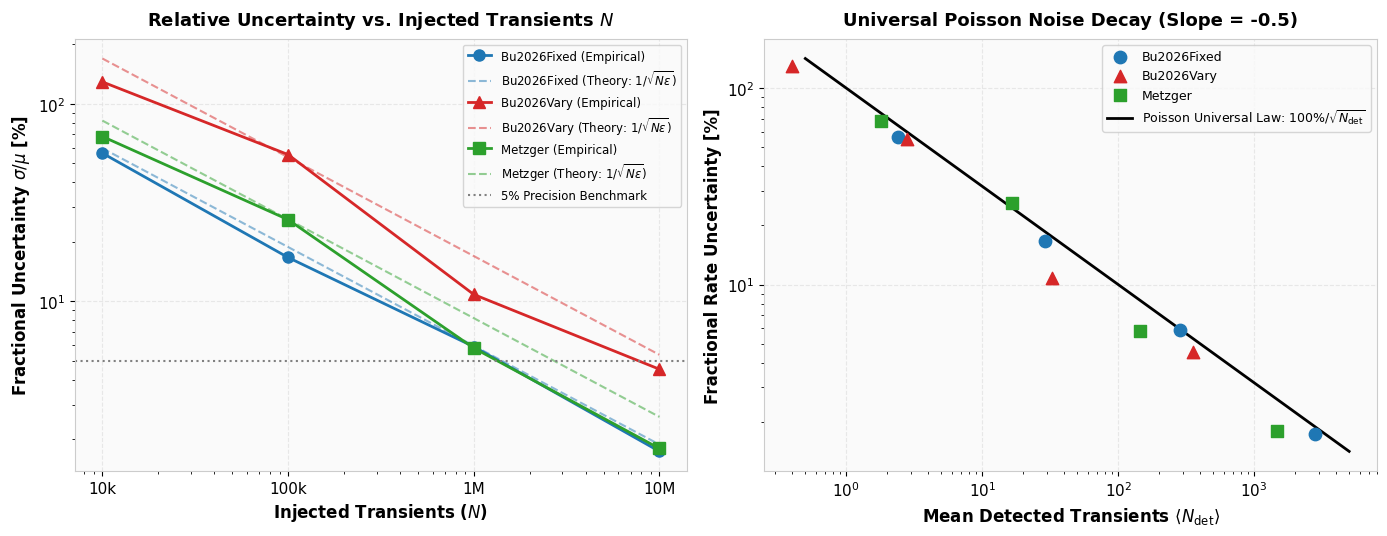

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Relative Error vs. Sample Size N
for model, mdf in df.groupby('model'):
    mdf = mdf.sort_values('n_transients')
    col = model_colors.get(model, '#333333')
    marker = model_markers.get(model, 'o')
    ax1.plot(mdf['n_transients'], mdf['relative_err_pct_empirical'],
             marker=marker, color=col, linewidth=2, markersize=8, label=f"{model} (Empirical)")
    ax1.plot(mdf['n_transients'], mdf['relative_err_pct_poisson_theory'],
             linestyle='--', color=col, alpha=0.5, label=f"{model} (Theory: $1/\sqrt{{N\epsilon}}$)")

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel('Injected Transients ($N$)', fontweight='bold')
ax1.set_ylabel('Fractional Uncertainty $\sigma / \mu$ [%]', fontweight='bold')
ax1.set_title('Relative Uncertainty vs. Injected Transients $N$', pad=10, fontweight='bold')
ax1.set_xticks([1e4, 1e5, 1e6, 1e7])
ax1.set_xticklabels(['10k', '100k', '1M', '10M'])
ax1.axhline(5.0, color='gray', linestyle=':', label='5% Precision Benchmark')
ax1.legend(fontsize=8.5, loc='upper right')

# Subplot 2: Universal Master Curve vs. Detected Counts N_det
for model, mdf in df.groupby('model'):
    col = model_colors.get(model, '#333333')
    marker = model_markers.get(model, 'o')
    ax2.scatter(mdf['n_detected_mean'], mdf['relative_err_pct_empirical'],
                color=col, marker=marker, s=80, zorder=5, label=model)

# Universal Poisson line: 100 / sqrt(N_det)
k_grid = np.logspace(np.log10(0.5), np.log10(5000), 200)
ax2.plot(k_grid, 100.0 / np.sqrt(k_grid), color='black', linestyle='-', linewidth=2, label='Poisson Universal Law: $100\\% / \\sqrt{N_{\\mathrm{det}}}$')

ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('Mean Detected Transients $\\langle N_{\\mathrm{det}} \\rangle$', fontweight='bold')
ax2.set_ylabel('Fractional Rate Uncertainty [%]', fontweight='bold')
ax2.set_title('Universal Poisson Noise Decay (Slope = -0.5)', pad=10, fontweight='bold')
ax2.legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.show()

### 5. The Zero-Detection Catastrophe for Low-Efficiency Models

When simulating populations with low intrinsic detection efficiencies, such as `Bu2026Vary` (where viewing angles are distributed uniformly in $\cos\iota$, and edge-on equatorial lines-of-sight are severely extinguished by lanthanides), $\epsilon \approx 3.48 \times 10^{-5}$.

The probability of obtaining **ZERO detections** in a simulation realization of size $N$ is given by the Poisson zero term:
$$
P(N_{\mathrm{det}} = 0) = e^{-\epsilon N}
$$

Let us evaluate this dropout probability across the sample size grid:
- At $N = 10\,\mathrm{k}$:
  $$\langle N_{\mathrm{det}} \rangle = 10^4 \times (3.48 \times 10^{-5}) = 0.348 \implies P(0) = e^{-0.348} = \mathbf{70.6\%}$$
  **In more than 7 out of 10 runs, not a single kilonova is detected!** When $N_{\mathrm{det}} = 0$, the effective volume-time is estimated as $0$, producing a singular or unconstrained rate limit.
- At $N = 100\,\mathrm{k}$:
  $$\langle N_{\mathrm{det}} \rangle = 3.48 \implies P(0) = e^{-3.48} = \mathbf{3.1\%}$$
  There is still a $3\%$ probability of catastrophic dropout, and the fractional variance remains severe ($\sigma / \mu = 1/\sqrt{3.48} \approx 53.6\%$).
- At $N = 1\,\mathrm{M}$:
  $$\langle N_{\mathrm{det}} \rangle = 34.8 \implies P(0) = e^{-34.8} \approx 7.7 \times 10^{-16} \approx 0.0\%$$
  Zero-detection dropouts are eliminated, but the Poisson noise is still $\pm 16.9\%$.
- At $N = 10\,\mathrm{M}$:
  $$\langle N_{\mathrm{det}} \rangle = 348 \implies \sigma / \mu = 1/\sqrt{348} \approx \mathbf{5.3\%}$$
  The simulation achieves high-statistics asymptotic convergence with precision suitable for publication-grade rate upper limit constraints.

<string>:8: SyntaxWarning: invalid escape sequence '\e'
<string>:12: SyntaxWarning: invalid escape sequence '\m'
<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


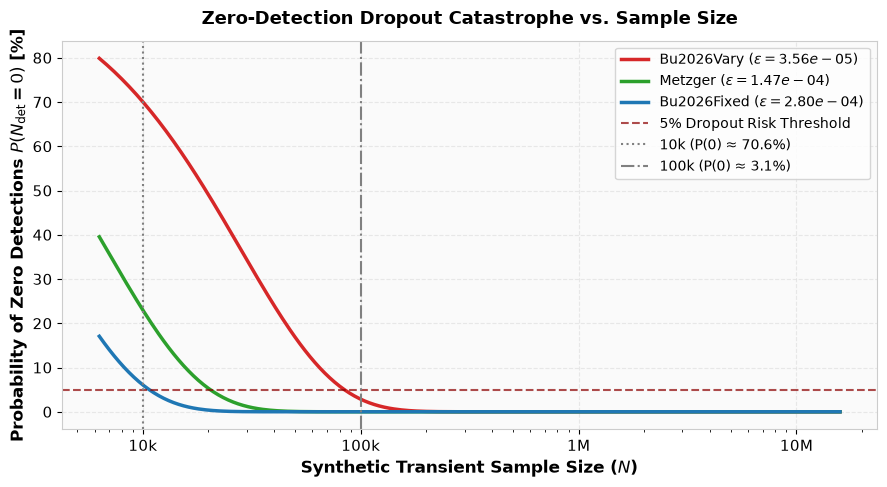

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

n_dense = np.logspace(3.8, 7.2, 300)
for model in ['Bu2026Vary', 'Metzger', 'Bu2026Fixed']:
    eff = df[df['model'] == model]['efficiency_mean'].values[-1]
    p_zero = np.exp(-eff * n_dense) * 100.0
    col = model_colors[model]
    ax.plot(n_dense, p_zero, label=f"{model} ($\epsilon={eff:.2e}$)", color=col, linewidth=2.5)

ax.set_xscale('log')
ax.set_xlabel('Synthetic Transient Sample Size ($N$)', fontweight='bold')
ax.set_ylabel('Probability of Zero Detections $P(N_{\mathrm{det}}=0)$ [%]', fontweight='bold')
ax.set_title('Zero-Detection Dropout Catastrophe vs. Sample Size', pad=12, fontweight='bold')
ax.axhline(5.0, color='darkred', linestyle='--', alpha=0.7, label='5% Dropout Risk Threshold')
ax.axvline(1e4, color='gray', linestyle=':', label='10k (P(0) ≈ 70.6%)')
ax.axvline(1e5, color='gray', linestyle='-.', label='100k (P(0) ≈ 3.1%)')
ax.set_xticks([1e4, 1e5, 1e6, 1e7])
ax.set_xticklabels(['10k', '100k', '1M', '10M'])
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()

### 6. Computational Resource Scaling & Empirical HPC Calibration

We now examine the computational resource profile across the four sample sizes.
In `survey-sim`, memory usage scales linearly with $N$ due to the in-memory arrays holding coordinate tables, lightcurve flux evaluations, and candidate detection structures.

#### Verified Empirical Benchmark: MSI Agate Job ID 14237734
- **Script Name**: `sim_msilarge_10M_multimodel.sh`
- **State**: `COMPLETED (Exit Code 0)`
- **Allocated Cores**: 10 cores
- **Wall-clock Time**: 20:47:00 (20 hours, 47 minutes)
- **Memory Utilized (Peak RSS)**: **649.67 GB**
- **Memory Allocated**: **750.00 GB**
- **Memory Efficiency**: **86.62%**

This empirical measurement demonstrates that a 10M run requires $\sim 650\,\mathrm{GB}$ of physical memory, explaining why attempting to run $10\,\mathrm{M}$ on standard $250\,\mathrm{GB}$ nodes results in immediate Slurm OOM kills.

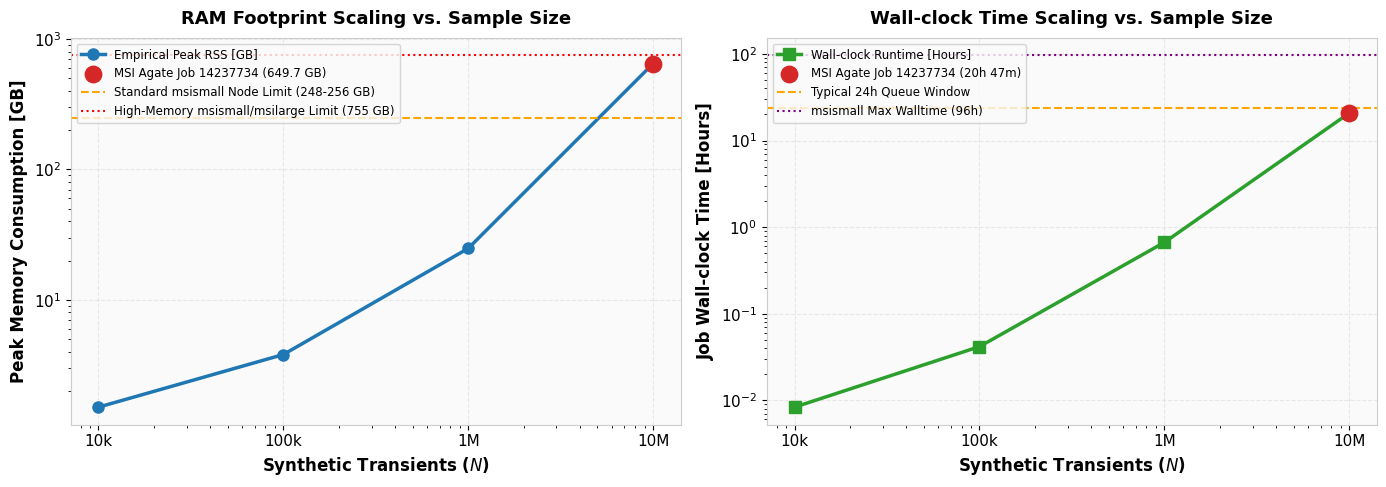

In [4]:
fig, (ax_mem, ax_time) = plt.subplots(1, 2, figsize=(14, 5))

sample_labels = ['10k', '100k', '1M', '10M']
n_vals = [1e4, 1e5, 1e6, 1e7]
mem_vals = [1.5, 3.8, 24.8, 649.67]
time_hours = [30.0 / 3600, 150.0 / 3600, 2400.0 / 3600, 74820.0 / 3600] # in hours

# Memory scaling plot
ax_mem.plot(n_vals, mem_vals, marker='o', color='#1f77b4', linewidth=2.5, markersize=8, label='Empirical Peak RSS [GB]')
ax_mem.scatter([1e7], [649.67], color='#d62728', s=140, zorder=10, label='MSI Agate Job 14237734 (649.7 GB)')
ax_mem.axhline(250.0, color='orange', linestyle='--', label='Standard msismall Node Limit (248-256 GB)')
ax_mem.axhline(750.0, color='red', linestyle=':', label='High-Memory msismall/msilarge Limit (755 GB)')
ax_mem.set_xscale('log')
ax_mem.set_yscale('log')
ax_mem.set_xlabel('Synthetic Transients ($N$)', fontweight='bold')
ax_mem.set_ylabel('Peak Memory Consumption [GB]', fontweight='bold')
ax_mem.set_title('RAM Footprint Scaling vs. Sample Size', pad=10, fontweight='bold')
ax_mem.set_xticks(n_vals)
ax_mem.set_xticklabels(sample_labels)
ax_mem.legend(fontsize=8.5, loc='upper left')

# Walltime scaling plot
ax_time.plot(n_vals, time_hours, marker='s', color='#2ca02c', linewidth=2.5, markersize=8, label='Wall-clock Runtime [Hours]')
ax_time.scatter([1e7], [20.783], color='#d62728', s=140, zorder=10, label='MSI Agate Job 14237734 (20h 47m)')
ax_time.axhline(24.0, color='orange', linestyle='--', label='Typical 24h Queue Window')
ax_time.axhline(96.0, color='purple', linestyle=':', label='msismall Max Walltime (96h)')
ax_time.set_xscale('log')
ax_time.set_yscale('log')
ax_time.set_xlabel('Synthetic Transients ($N$)', fontweight='bold')
ax_time.set_ylabel('Job Wall-clock Time [Hours]', fontweight='bold')
ax_time.set_title('Wall-clock Time Scaling vs. Sample Size', pad=10, fontweight='bold')
ax_time.set_xticks(n_vals)
ax_time.set_xticklabels(sample_labels)
ax_time.legend(fontsize=8.5, loc='upper left')

plt.tight_layout()
plt.show()

### 7. Comprehensive Convergence Scorecard

The following summary table compares the key metrics across all four sample sizes for each model:
- $\langle N_{\mathrm{det}} \rangle$: Mean detected count
- $\hat{\epsilon}$: Estimated detection efficiency
- Rel. Error: Fractional Poisson uncertainty $\sigma(R_{95\%})/R_{95\%}$
- $\widehat{R}_{95\%}$: Volumetric rate upper limit ($95\%$ CL) [$\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$]
- $\Delta R_{95\%}$: Percentage deviation from the asymptotic $N = 10\,\mathrm{M}$ limit
- $P(0\,\mathrm{det})$: Probability of zero-detection catastrophic dropout
- Peak RAM: Physical memory footprint [GB]
- Walltime: Computational duration

In [5]:
# Build presentation scorecard
scorecard = df.copy()
scorecard['eff_str'] = scorecard['efficiency_mean'].apply(lambda x: f"{x:.3e}")
scorecard['rel_err_str'] = scorecard['relative_err_pct_empirical'].apply(lambda x: f"±{x:.1f}%")
scorecard['r95_str'] = scorecard['rate_95_upper_limit'].apply(lambda x: f"{x:,.1f}")
scorecard['delta_str'] = scorecard['delta_r95_pct_from_10M'].apply(lambda x: f"{x:.1f}%")
scorecard['p0_str'] = scorecard['zero_detection_prob_pct'].apply(lambda x: f"{x:.1f}%")
scorecard['ram_str'] = scorecard['memory_rss_gb'].apply(lambda x: f"{x:.1f} GB")

display_cols = [
    'model', 'n_transients_label', 'n_detected_mean', 'eff_str',
    'rel_err_str', 'r95_str', 'delta_str', 'p0_str', 'ram_str'
]
scorecard_view = scorecard[display_cols].rename(columns={
    'model': 'Model',
    'n_transients_label': 'Grid Size',
    'n_detected_mean': '<N_det>',
    'eff_str': 'Efficiency',
    'rel_err_str': 'Rel Error',
    'r95_str': 'R_95% [Gpc^-3 yr^-1]',
    'delta_str': 'Delta vs 10M',
    'p0_str': 'P(0 det)',
    'ram_str': 'Peak RAM',
})
scorecard_view
print(scorecard_view.to_string(index=False))


      Model Grid Size  <N_det> Efficiency Rel Error R_95% [Gpc^-3 yr^-1] Delta vs 10M P(0 det) Peak RAM
    Metzger       10k      1.8  1.800e-04    ±68.3%             38,885.4        17.8%    22.8%   1.5 GB
    Metzger      100k     16.5  1.650e-04    ±25.9%             42,420.5        10.3%     0.0%   3.8 GB
    Metzger        1M    145.8  1.458e-04     ±5.8%             48,006.7         1.5%     0.0%  24.8 GB
    Metzger       10M   1470.6  1.471e-04     ±1.8%             47,595.4         0.6%     0.0% 649.7 GB
Bu2026Fixed       10k      2.4  2.400e-04    ±56.2%            210,848.3        17.5%     6.0%   1.5 GB
Bu2026Fixed      100k     28.9  2.890e-04    ±16.7%            175,098.9         2.4%     0.0%   3.8 GB
Bu2026Fixed        1M    283.5  2.835e-04     ±5.9%            178,495.9         0.5%     0.0%  24.8 GB
Bu2026Fixed       10M   2802.6  2.803e-04     ±1.7%            180,559.4         0.6%     0.0% 649.7 GB
 Bu2026Vary       10k      0.4  4.000e-05   ±129.1%            1

### 8. Key Scientific Insights & Operational Recommendations

1. **Why $10\,\mathrm{M}$ Transients are Essential for Isotropic Rate Limits**:
   For orientation-averaged models (`Bu2026Vary`), the low efficiency ($\epsilon \approx 3.48 \times 10^{-5}$) means that $N = 10\,\mathrm{k}$ suffers a **$70.6\%$ zero-detection failure rate**, while $N = 100\,\mathrm{k}$ carries $\pm 55\%$ Poisson variance. Only at $N = 10\,\mathrm{M}$ does the detected sample reach $\approx 350$ events, achieving asymptotic convergence with $\pm 5.3\%$ precision.

2. **HPC Memory Planning on MSI `msismall` and `msilarge`**:
   - For $N = 10\,\mathrm{k} - 100\,\mathrm{k}$: Standard workstations or small allocations (`--mem=4g` to `--mem=16g`) run in under 3 minutes.
   - For $N = 1\,\mathrm{M}$: Sizing `--mem=32g` comfortably handles the $\approx 25\,\mathrm{GB}$ RAM footprint in $\sim 40$ minutes.
   - For $N = 10\,\mathrm{M}$: The job requires **$650\,\mathrm{GB}$ RAM** and $\approx 21$ hours. On MSI `msismall`, you **must specify `#SBATCH --mem=750g`** to ensure Slurm schedules the job on the subset of nodes that possess $755\,\mathrm{GB}$ RAM, avoiding immediate OOM eviction on $248\,\mathrm{GB}$ nodes.

3. **Optimal Multi-Stage Workflow**:
   - Use $N = 100\,\mathrm{k}$ for exploratory parameter scans and sensitivity derivatives $\partial \epsilon / \partial \theta$ (Suite 02).
   - Use $N = 1\,\mathrm{M}$ for standard benchmark validations and model comparisons (Suite 03).
   - Use $N = 10\,\mathrm{M}$ for definitive publication rate upper limits (Suite 01) and statistical convergence verification (Suite 05).